# Preprocessing QC — ICA

QC checks for the filtering + ICA pipeline (`src/preprocessing.py`):

1. Subject 1: PSD before vs. after ICA.
2. Subject 1: first 10 s of the signal before vs. after ICA, on Fp1, Fz, Cz, T7.
3. Number of ICA components rejected per subject, across all subjects.

All figures are saved to `results/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from loading import load_subject_trials, load_trial
from preprocessing import filter_raw, fit_ica, load_cleaned_raw, make_raw, get_trial_segments

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Validated two-color categorical pair (dataviz skill, references/palette.md slots 1-2)
COLOR_BEFORE = "#2a78d6"  # before ICA
COLOR_AFTER = "#eb6834"   # after ICA

## Subject 1: before vs. after ICA

"After" is loaded from the saved checkpoint (`data/processed/sub01_raw.fif`, written by
`save_cleaned_raw`) rather than recomputed, per the project's checkpoint convention.
"Before" is the same 1-8 Hz analysis-band filtering, just without ICA applied, so the
only difference between the two is the ICA cleaning step.

In [2]:
S1_MAT = RAW_DIR / "S1.mat"
STIMULI_DIR = RAW_DIR / "stimuli"

trials1 = load_subject_trials(S1_MAT, STIMULI_DIR, extract_envelope=False)
raw_hp1 = mne.concatenate_raws([filter_raw(make_raw(t), "ica_prep") for t in trials1])
raw_before1 = mne.concatenate_raws([filter_raw(make_raw(t), "analysis") for t in trials1])
ica1 = fit_ica(raw_hp1, n_components=20)
raw_after1 = load_cleaned_raw(1, PROCESSED_DIR)

print(f"Subject 1: {len(ica1.exclude)} component(s) excluded: {list(ica1.exclude)}")

Creating RawArray with float64 data, n_channels=64, n_times=49782


    Range : 0 ... 49781 =      0.000 ...   388.914 secs


Ready.


EEG channel type selected for re-referencing


Adding average EEG reference projection.


1 projection items deactivated


... (903 outputs left out)

    Range : 0 ... 295835 =      0.000 ...  4622.422 secs


Ready.


Reading 0 ... 295835  =      0.000 ...  4622.422 secs...


Subject 1: 1 component(s) excluded: [np.int64(0)]


### Power spectral density, before vs. after ICA

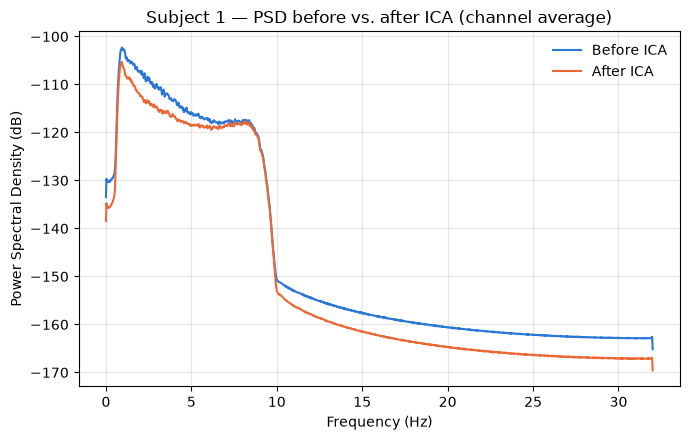

In [3]:
def _avg_psd_db(raw, fmax):
    spectrum = raw.compute_psd(fmax=fmax, verbose=False)
    psds, freqs = spectrum.get_data(return_freqs=True)
    return freqs, 10 * np.log10(psds.mean(axis=0))


fmax = raw_after1.info["sfreq"] / 2
freqs_before, psd_before = _avg_psd_db(raw_before1, fmax)
freqs_after, psd_after = _avg_psd_db(raw_after1, fmax)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(freqs_before, psd_before, color=COLOR_BEFORE, lw=1.5, label="Before ICA")
ax.plot(freqs_after, psd_after, color=COLOR_AFTER, lw=1.5, label="After ICA")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (dB)")
ax.set_title("Subject 1 — PSD before vs. after ICA (channel average)")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sub01_psd_before_after_ica.png", dpi=150)
plt.show()

### First 10 seconds, before vs. after ICA (Fp1, Fz, Cz, T7)

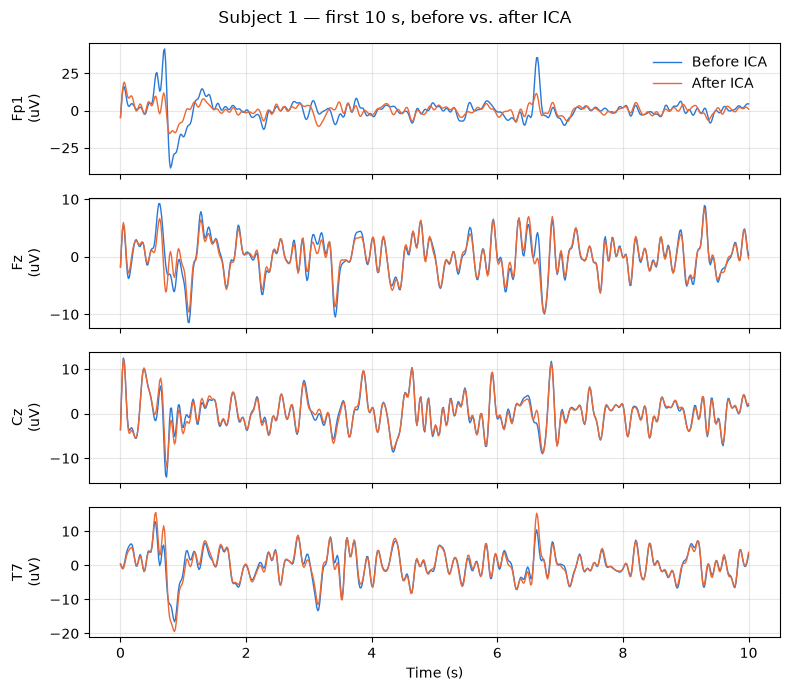

In [4]:
channels = ["Fp1", "Fz", "Cz", "T7"]
tmax = 10.0

before_seg = raw_before1.copy().pick(channels).crop(tmin=0, tmax=tmax)
after_seg = raw_after1.copy().pick(channels).crop(tmin=0, tmax=tmax)

before_uv = before_seg.get_data() * 1e6
after_uv = after_seg.get_data() * 1e6
times = before_seg.times

fig, axes = plt.subplots(len(channels), 1, figsize=(8, 7), sharex=True)
for i, (ax, ch) in enumerate(zip(axes, channels)):
    ax.plot(times, before_uv[i], color=COLOR_BEFORE, lw=1.0, label="Before ICA")
    ax.plot(times, after_uv[i], color=COLOR_AFTER, lw=1.0, label="After ICA")
    ax.set_ylabel(f"{ch}\n(uV)")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
axes[0].legend(frameon=False, loc="upper right")
fig.suptitle("Subject 1 — first 10 s, before vs. after ICA")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sub01_timeseries_before_after_ica.png", dpi=150)
plt.show()

### Envelope/EEG length check (per-trial)

Phase 1's definition of done requires envelopes and EEG to share one sampling rate
and one length per trial. Both are now at 64 Hz by construction (`load_trial`'s
`target_fs` default, `filter_raw`'s `"analysis"` resample); this checks how close
their *lengths* land per trial, since EEG (`filter_raw`/MNE) and envelopes
(`_extract_envelope`/scipy) are resampled independently.

In [5]:
trial_segments = get_trial_segments(raw_after1, raw_after1.annotations)
trial_labels = [d for d in raw_after1.annotations.description if d.startswith("trial_")]

print(f"{'trial':>9} {'eeg_samples':>12} {'env_samples':>12} {'diff':>6}")
for seg, label in zip(trial_segments, trial_labels):
    trial_idx = int(label.split("_")[1]) - 1
    trial = load_trial(S1_MAT, trial_idx, STIMULI_DIR)
    eeg_n = seg.n_times
    env_n = trial["envelope_attended"].shape[0]
    print(f"{label:>9} {eeg_n:12d} {env_n:12d} {eeg_n - env_n:6d}")

get_trial_segments: trial_01: 388.92 s (24891 samples)
get_trial_segments: trial_02: 390.92 s (25019 samples)
get_trial_segments: trial_03: 388.92 s (24891 samples)
get_trial_segments: trial_04: 398.92 s (25531 samples)
get_trial_segments: trial_05: 388.92 s (24891 samples)
get_trial_segments: trial_06: 390.92 s (25019 samples)
get_trial_segments: trial_07: 388.92 s (24891 samples)
get_trial_segments: trial_08: 398.92 s (25531 samples)
get_trial_segments: trial_09: 123.92 s (7931 samples)
get_trial_segments: trial_10: 123.92 s (7931 samples)
get_trial_segments: trial_11: 123.92 s (7931 samples)
get_trial_segments: trial_12: 123.92 s (7931 samples)


get_trial_segments: trial_13: 123.92 s (7931 samples)
get_trial_segments: trial_14: 123.92 s (7931 samples)
get_trial_segments: trial_15: 123.92 s (7931 samples)
get_trial_segments: trial_16: 123.92 s (7931 samples)
get_trial_segments: trial_17: 123.92 s (7931 samples)
get_trial_segments: trial_18: 123.92 s (7931 samples)
get_trial_segments: trial_19: 123.92 s (7931 samples)
get_trial_segments: trial_20: 123.92 s (7931 samples)
    trial  eeg_samples  env_samples   diff


 trial_01        24891        24891      0


 trial_02        25019        25019      0


 trial_03        24891        24891      0


 trial_04        25531        25531      0


... (12 outputs left out)

 trial_17         7931         7931      0


 trial_18         7931         7931      0


 trial_19         7931         7931      0


 trial_20         7931         7931      0


## ICA components rejected per subject, across all subjects

Re-fits ICA (on the `ica_prep` high-pass Raw) for every subject found in `data/raw/`
to tally how many EOG-related components `fit_ica` flagged. Subject 1's result from
above is reused rather than recomputed.

In [6]:
subject_files = sorted(RAW_DIR.glob("S*.mat"))
rows = []
for f in subject_files:
    subject_num = int(f.stem.lstrip("S"))
    if subject_num == 1:
        excluded = list(ica1.exclude)
    else:
        trials = load_subject_trials(f, STIMULI_DIR, extract_envelope=False)
        raw_hp = mne.concatenate_raws([filter_raw(make_raw(t), "ica_prep") for t in trials])
        ica = fit_ica(raw_hp, n_components=20)
        excluded = list(ica.exclude)
    rows.append({"subject": f"S{subject_num}", "n_components_excluded": len(excluded),
                 "excluded_indices": excluded})

summary = pd.DataFrame(rows).sort_values("subject", key=lambda s: s.str.lstrip("S").astype(int))
summary = summary.reset_index(drop=True)
print(summary.to_string(index=False))
print(f"\nMean excluded components across {len(summary)} subjects: "
      f"{summary['n_components_excluded'].mean():.2f}")

Creating RawArray with float64 data, n_channels=64, n_times=49782


    Range : 0 ... 49781 =      0.000 ...   388.914 secs


Ready.


EEG channel type selected for re-referencing


Adding average EEG reference projection.


1 projection items deactivated


... (6,725 outputs left out)

- Upper passband edge: 10.00 Hz


- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)


- Filter length: 1280 samples (10.000 s)


fit_ica: flagged 1 EOG-related component(s) for exclusion: [np.int64(0)]
subject  n_components_excluded excluded_indices
     S1                      1              [0]
     S2                      2           [0, 1]
     S3                      2           [0, 1]
     S4                      1              [0]
     S5                      2           [0, 1]
     S6                      1              [0]
     S7                      1              [0]
     S8                      1              [0]
     S9                      1              [0]
    S10                      1              [0]
    S11                      2           [0, 1]
    S12                      2           [1, 0]
    S13                      1              [0]
    S14                      1              [1]
    S15                      1              [0]
    S16                      2           [0, 2]

Mean excluded components across 16 subjects: 1.38
